# VLM privacy benchmark
    Independent Colab notebook. Select a GPU runtime and run cells in order. No other
    notebook or Git clone is needed. This notebook contains its own verified source
    snapshot and fixed 25-document/25-general cohort. Results go to your existing Drive
    destination. Training is not performed. **Fresh GPU execution is still pending.**

    Models: qwen3_vl, qwen25_vl, llama32_vision. Each profile uses an isolated worker environment.
    Florence does not require FlashAttention. Dots retains the FlashAttention profile
    and needs an Ampere-or-newer GPU, such as L4/A100. Installation can still take time;
    the notebook displays native output and periodic elapsed-time messages.

## 1 Restore the bundled implementation

In [1]:
from pathlib import Path
import base64,hashlib,io,os,sys,zipfile
PROJECT = Path('/content/Show-Me-The-Leak-v2') if Path('/content').exists() else Path.cwd()
PROJECT.mkdir(parents=True,exist_ok=True)
PAYLOAD = '...'
data=base64.b64decode(PAYLOAD)
assert hashlib.sha256(data).hexdigest()=='c3571dd7710329cff079fcac70abbe9e0f2ab6dfb4ea9b6d2184553818b9b3c1', 'Embedded source checksum mismatch'
with zipfile.ZipFile(io.BytesIO(data)) as bundle:
    for member in bundle.namelist():
        target=(PROJECT/member).resolve();target.relative_to(PROJECT.resolve())
        target.parent.mkdir(parents=True,exist_ok=True)
        if not target.exists() or target.read_bytes()!=bundle.read(member):target.write_bytes(bundle.read(member))
sys.path.insert(0,str(PROJECT/'src'))
for name in list(sys.modules):
    if name=='leakbench' or name.startswith('leakbench.'):del sys.modules[name]
os.environ['PYTHONPATH']=str(PROJECT/'src')
os.environ.setdefault('HF_HOME',str(PROJECT/'.model_cache/huggingface'))
os.environ['MAX_JOBS']='2'
os.environ['NVCC_THREADS']='2'
print('Verified source snapshot ready:', PROJECT)

Verified source snapshot ready: /content/Show-Me-The-Leak-v2


## 2 Install notebook dependencies and verify GPU

In [2]:
from leakbench.execution import run_command
run_command([sys.executable,'-m','pip','install','Pillow==11.3.0','pandas==2.2.3',
             'matplotlib==3.10.6','tqdm==4.67.1'], 'Notebook dependencies', timeout=900)
import subprocess
gpu=subprocess.run(['nvidia-smi'],capture_output=True,text=True,timeout=20)
print(gpu.stdout)
if gpu.returncode:raise RuntimeError('Choose a GPU runtime in Colab before continuing.')

{"time": "2026-10-19T23:00:43.546249+00:00", "message": "Notebook dependencies starting"}
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 126.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 9.0 MB/s eta 0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
{"time": "2026-10-19T23:00:53.069715+00:00", "message": "Notebook dependencies completed", "elapsed_seconds": 9.52}
Mon Oct 19 23:00:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------

## 3 Connect existing Drive backup and optional Hugging Face secret

In [3]:
from google.colab import drive, userdata
drive.mount('/content/drive')
from leakbench.cloud import DRIVE_ROOT, verified_copy_tree, backup
print('Existing backup root:', DRIVE_ROOT)
try:
    token=userdata.get('HF_TOKEN')
    if token:os.environ['HF_TOKEN']=token
    print('Hugging Face secret loaded without printing its value.')
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    print('No HF_TOKEN secret available. Public models may run; gated Llama needs authorized access.')

Mounted at /content/drive
Existing backup root: /content/drive/MyDrive/Leak_Benchmark_Results
No HF_TOKEN secret available. Public models may run; gated Llama needs authorized access.


## 4 Prepare and validate the frozen cohort

In [4]:
from leakbench.dataset import prepare_subset,validate_subset,records
from leakbench.common import read_json
dataset_dir=PROJECT/'data/vispr_eval_50'
cloud_dataset=DRIVE_ROOT/'benchmark_v2/data/vispr_eval_50'
uploaded_subset=Path('/content/vispr_eval_50.zip')
if not (dataset_dir/'manifest.csv').exists() and (cloud_dataset/'manifest.csv').exists():
    verified_copy_tree(cloud_dataset,dataset_dir)
if not (dataset_dir/'manifest.csv').exists() and uploaded_subset.exists():
    with zipfile.ZipFile(uploaded_subset) as archive:
        for entry in archive.infolist():
            target=(PROJECT/'data'/entry.filename).resolve();target.relative_to((PROJECT/'data').resolve())
        archive.extractall(PROJECT/'data')
dataset_dir=prepare_subset(PROJECT,PROJECT/'configs/selection.json')
display(read_json(dataset_dir/'validation.json'))
verified_copy_tree(dataset_dir,cloud_dataset)

Validate fixed cohort:   0%|          | 0/50 [00:00<?, ?image/s]

{"time": "2026-10-19T23:01:24.854700+00:00", "message": "Dataset validated", "status": "validated", "count": 50, "documents": 25, "general": 25, "selection_fingerprint": "0beae8a380049243b74c8c9e2605ef3d01ecbdfcdfaa14f99dc74e8a3cb50b72", "near_duplicate_candidates": [], "annotation_scope": "image labels only; no verified reference boxes or transcripts"}


{'status': 'validated',
 'count': 50,
 'documents': 25,
 'general': 25,
 'selection_fingerprint': '0beae8a380049243b74c8c9e2605ef3d01ecbdfcdfaa14f99dc74e8a3cb50b72',
 'near_duplicate_candidates': [],
 'annotation_scope': 'image labels only; no verified reference boxes or transcripts'}

Cloud copy and verify:   0%|          | 0/103 [00:00<?, ?file/s]

{"time": "2026-10-19T23:01:26.748129+00:00", "message": "Drive filesystem backup verified", "files": 103, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/data/vispr_eval_50", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}


[{'path': 'annotations/document_1.json',
  'sha256': '3cf6df4db76f769a2abeb9709d4278780f8924fff98725638835563b818d12be',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_10.json',
  'sha256': 'caaaf3997e44d29a8a7758b45139a2137e76244f9b007734cfc8f478d2c55392',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_11.json',
  'sha256': 'f7c4c9fddaf5eff8aa908c920e730f2640a229c9bc2447cbeb6babc60e188052',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_12.json',
  'sha256': '6123a21440a47da664620c0259c84955d014efd629084b77fb48d87179f91c6e',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_13.json',
  'sha256': '7f6d90788ac9bc98a7c73b1558b903245d07880069e202621ad00edf65860ba8',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_14.json',
  'sha256': 'a47d9c77ffe08b483120836a7dc3bc8ed79b9ccb5b6209c83784497acddeb1a8',
  'status': 'copied_and_verified'},
 {'path': 'annotations/document_15.json',
  'sha256':

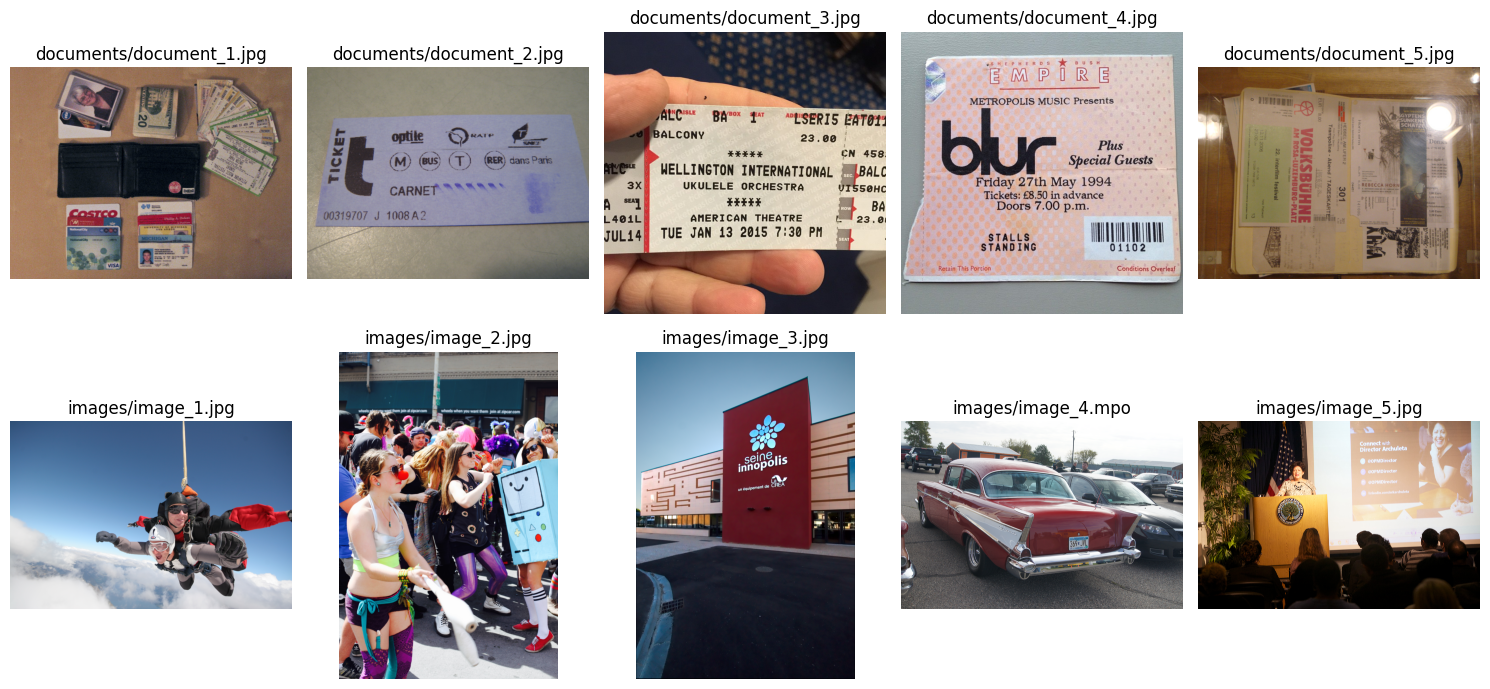

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
cohort=records(dataset_dir)
fig,axes=plt.subplots(2,5,figsize=(15,7))
for ax,row in zip(axes.flat,[r for r in cohort if r['category']=='documents'][:5]+[r for r in cohort if r['category']=='images'][:5]):
    with Image.open(row['image_path']) as im:ax.imshow(im.copy())
    ax.set_title(row['filename']);ax.axis('off')
plt.tight_layout();plt.show()

## 5 Configure the experiment
    The default preserves 1280 pixels, 4096 output tokens and one format retry.
    The old hidden redacted-image audit is excluded as an explicit protocol change.
    One image per batch supports heterogeneous model APIs and isolates failures.
    Timeouts stop stalled workers; they are limits, not promised runtimes. A timeout
    remains an error and blocks continuation when it occurs in the pilot.
    Start with the two-image pilot. Review its timing, predictions and redactions,
    then set RUN_FULL_BENCHMARK=True and rerun sections 5 onward for all 50 images.

In [6]:
from leakbench.orchestrate import start_run,execute_category
CATEGORY='vlm'
RUN_FULL_BENCHMARK=False
CONFIG={'models':['qwen3_vl', 'qwen25_vl', 'llama32_vision'], 'max_input_edge':1280,'max_new_tokens':4096,
         'format_retries':1,'load_in_4bit':True,'redaction_padding':0.01,
         'audit_redacted':False,'batch_size':1,'image_timeout_seconds':600,
         'run_timeout_seconds':43200,'download_timeout_seconds':3600,'load_timeout_seconds':1800}
run_dir=start_run(PROJECT,CATEGORY,CONFIG,resume=True)
display(read_json(run_dir/'run_config.json'))

{'category': 'vlm',
 'settings': {'models': ['qwen3_vl', 'qwen25_vl', 'llama32_vision'],
  'max_input_edge': 1280,
  'max_new_tokens': 4096,
  'format_retries': 1,
  'load_in_4bit': True,
  'redaction_padding': 0.01,
  'audit_redacted': False,
  'batch_size': 1,
  'image_timeout_seconds': 600,
  'run_timeout_seconds': 43200,
  'download_timeout_seconds': 3600,
  'load_timeout_seconds': 1800},
 'selection_fingerprint': '0beae8a380049243b74c8c9e2605ef3d01ecbdfcdfaa14f99dc74e8a3cb50b72',
 'source_hashes': {'src/leakbench/__init__.py': '1cb25cf367d9ea1eb9a9d1307c25b1d14d7fe75545407547bf791d76df6dd989',
  'src/leakbench/adapters.py': '43872f58c8a88bbb91e07e780a992898be37d64cfa090ecfbd0774f09090c6bc',
  'src/leakbench/cloud.py': '0cb55ab46fd72a8832036c0039707cd713c2cda48f8d163a5e340790666f5099',
  'src/leakbench/common.py': 'ec9fdda0e4322531cc91b660ace9e31088c05fa148aae55a25e5b58e911ae67d',
  'src/leakbench/dataset.py': '582b03a8f6388ffa0c294b64a6e3f91e92e25adaf240b9d0dc8dbad1b105fa03',
  's

## 6 Model setup then timed pilot and full benchmark
    Downloads, loading and processing are separate visible stages. Each worker checks
    actual CUDA placement and records GPU utilization and peak memory. A pilot requires
    one valid document and one valid general-image result before that model continues.
    Successful pilot outputs are reused; a full worker loads once for the remaining
    images. Other models can proceed if one fails. Model initialization and native
    imports live in the bundled leakbench adapters and are included in the run source.

In [7]:
report_dir=execute_category(PROJECT,run_dir,full=RUN_FULL_BENCHMARK,save_cloud=True)

Cloud copy and verify:   0%|          | 0/103 [00:00<?, ?file/s]

{"time": "2026-10-19T23:01:32.974759+00:00", "message": "Drive filesystem backup verified", "files": 103, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/data/vispr_eval_50", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}


Cloud copy and verify:   0%|          | 0/20 [00:00<?, ?file/s]

{"time": "2026-10-19T23:01:33.200881+00:00", "message": "Drive filesystem backup verified", "files": 20, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/results/vlm/20261019T230132317596Z", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}
{"time": "2026-10-19T23:01:33.202024+00:00", "message": "Install environment manager starting"}
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 115.7 MB/s eta 0:00:00
{"time": "2026-10-19T23:01:37.423939+00:00", "message": "Install environment manager completed", "elapsed_seconds": 4.22}
{"time": "2026-10-19T23:01:37.424739+00:00", "message": "vlm setup stage 1/4 starting"}
Installed Python 3.11.13 in 1.28s
 + cpython-3.11.13-linux-x86_64-gnu (python3.11)
{"time": "2026-10-19T23:01:38.772443+00:00", "message": "vlm setup stage 1/4 completed", "elapsed_seconds": 1.35}
{"time": "2026-10-19T23:01:38.772889+00:00", "message": "vlm setup stage 2/4 star

Cloud copy and verify:   0%|          | 0/103 [00:00<?, ?file/s]

...

{"time": "2026-10-19T23:08:26.321770+00:00", "message": "Drive filesystem backup verified", "files": 76, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/results/vlm/20261019T230132317596Z", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}
{"time": "2026-10-19T23:08:26.323319+00:00", "message": "llama32_vision pilot starting"}

Validate fixed cohort: 100%|██████████| 50/50 [00:06<00:00,  7.92image/s]
{"time": "2026-10-19T23:08:34.640102+00:00", "message": "Dataset validated", "status": "validated", "count": 50, "documents": 25, "general": 25, "selection_fingerprint": "0beae8a380049243b74c8c9e2605ef3d01ecbdfcdfaa14f99dc74e8a3cb50b72", "near_duplicate_candidates": [], "annotation_scope": "image labels only; no verified reference boxes or transcripts"}
{"time": "2026-10-19T23:08:34.644003+00:00", "message": "model_download", "stage": "model_download", "started_at": "2026-10-19T23:08:34.643595+0

Cloud copy and verify:   0%|          | 0/103 [00:00<?, ?file/s]

{"time": "2026-10-19T23:08:36.911873+00:00", "message": "Drive filesystem backup verified", "files": 103, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/data/vispr_eval_50", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}


Cloud copy and verify:   0%|          | 0/82 [00:00<?, ?file/s]

{"time": "2026-10-19T23:08:37.457968+00:00", "message": "Drive filesystem backup verified", "files": 82, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/results/vlm/20261019T230132317596Z", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}
{"time": "2026-10-19T23:08:37.460615+00:00", "message": "Calculate metrics and assemble reports", "stage": "Calculate metrics and assemble reports", "started_at": "2026-10-19T23:08:37.460591+00:00", "elapsed_seconds": 0.0}
{"time": "2026-10-19T23:08:37.647897+00:00", "message": "Reports exported", "path": "/content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports", "status": "partial_or_pending"}
{"time": "2026-10-19T23:08:37.648715+00:00", "message": "Calculate metrics and assemble reports finished", "elapsed_seconds": 0.19}


## 7 Metrics comparison and final summary

In [8]:
import pandas as pd
from IPython.display import display,Markdown,HTML
summary=read_json(report_dir/'summary.json')
display(Markdown('## Final report\n\n'+summary['conclusion']+'\n\n'+summary['limitations']))
display(pd.DataFrame(summary['coverage']))
quality=pd.read_csv(report_dir/'full_taxonomy_summaries.csv')
display(quality[(quality.stratum=='all') & (quality.scope=='common_successful')])
display(pd.read_csv(report_dir/'runtime.csv'))
for name in ['phase_timings','image_timings']:
    if (report_dir/f'{name}.csv').exists():
        display(Markdown('### '+name.replace('_',' ')))
        display(pd.read_csv(report_dir/f'{name}.csv').head(10))
        print('Complete timing table:',report_dir/f'{name}.csv')
for scope in ['full_taxonomy','shared_text_scope']:
    attribute_table=pd.read_csv(report_dir/f'{scope}_per_attribute.csv')
    display(Markdown('### Most missed attributes '+scope))
    display(attribute_table[(attribute_table.scope=='all_successful') & (attribute_table.stratum=='all')]
            .sort_values('missed_count',ascending=False).head(15))
print('HTML report with image links:',report_dir/'report.html')
print('Source run:',run_dir)

## Final report

Best model is pending: complete valid coverage is not available for every requested model. The common-successful tables compare identical images; other tables are diagnostic, not a fair ranking.

VISPR supplies image-level labels only. Missing labels are image-attribute occurrences, not physical regions. Extra labels are unannotated predictions, not confirmed false positives. IoU, reference redaction coverage, CER, WER and ROUGE-L are unavailable until independently verified region/transcript annotations are supplied. OCR scores measure native OCR plus the fixed English text rules. Review images for unlocalized predictions and excess masking. This is a curated training-split diagnostic cohort, not a held-out generalization test. The cohort differs from the old sample by 11 images.

,model_key,stratum,expected_images,attempted_images,successful_images,failed_images,not_attempted_images,success_rate_of_attempts,coverage_of_sample
0,qwen3_vl,all,50,2,2,0,48,1.0,0.04
1,qwen25_vl,all,50,2,2,0,48,1.0,0.04
2,llama32_vision,all,50,0,0,0,50,NaN,0.00


,model_key,stratum,scope,n_images,n_evaluated_labels,n_supported_labels,true_positives,unannotated_count,missed_count,ground_truth_positive_count,...,localization_fp,localization_fn,localization_precision,localization_recall,localization_f1,mean_matched_iou,n_text_images,mean_rouge_l_f1,corpus_cer,corpus_wer
1,qwen3_vl,all,common_successful,0,67,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
7,qwen25_vl,all,common_successful,0,67,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
13,llama32_vision,all,common_successful,0,67,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN


,model,timed_images,median_detection_seconds,historical_median_detection_seconds,median_image_seconds,p95_image_seconds,images_per_second_excluding_load,loading_and_download_by_phase,peak_gpu_memory_bytes
0,qwen3_vl,2,12.325700,"[3.420413840499805, 1.954106855999271]",15.523207,26.182653,0.064420,{'pilot': {'download_seconds': 44.180055298999...,7.159887e+09
1,qwen25_vl,2,1.220438,"[1.9199528574999931, 1.9170078945007845]",4.406303,4.849251,0.226948,{'pilot': {'download_seconds': 39.366409766999...,6.624541e+09
2,llama32_vision,0,NaN,[31.362795246999667],NaN,NaN,NaN,{},NaN


### phase timings

...

### Most missed attributes full_taxonomy

,model_key,stratum,scope,attribute_id,support,predicted_count,true_positives,missed_count,unannotated_count,precision,recall,f1,category
11,qwen3_vl,all,all_successful,a1_age_approx,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
35,qwen3_vl,all,all_successful,a4_gender,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
66,qwen3_vl,all,all_successful,a9_face_complete,2,0,0,2,0,0.0,0.0,0.0,Biometric Data
437,qwen25_vl,all,all_successful,a4_gender,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
413,qwen25_vl,all,all_successful,a1_age_approx,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
468,qwen25_vl,all,all_successful,a9_face_complete,2,0,0,2,0,0.0,0.0,0.0,Biometric Data
19,qwen3_vl,all,all_successful,a29_ausweis,1,0,0,1,0,0.0,0.0,0.0,Legal Identifiers
7,qwen3_vl,all,all_successful,a16_race,1,0,0,1,0,0.0,0.0,0.0,Personal Metadata
21,qwen3_vl,all,all_successful,a30_credit_card,1,0,0,1,0,0.0,0.0,0.0,Financial Information
51,qwen3_vl,all,all_successful,a6_hair_color,1,0,0,1,0,0.0,0.0,0.0,Biometric Data


### Most missed attributes shared_text_scope

,model_key,stratum,scope,attribute_id,support,predicted_count,true_positives,missed_count,unannotated_count,precision,recall,f1,category
18,qwen3_vl,all,all_successful,a4_gender,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
180,qwen25_vl,all,all_successful,a4_gender,2,0,0,2,0,0.0,0.0,0.0,Personal Metadata
8,qwen3_vl,all,all_successful,a29_ausweis,1,0,0,1,0,0.0,0.0,0.0,Legal Identifiers
15,qwen3_vl,all,all_successful,a38_ticket,1,0,0,1,0,0.0,0.0,0.0,Financial Information
9,qwen3_vl,all,all_successful,a30_credit_card,1,0,0,1,0,0.0,0.0,0.0,Financial Information
22,qwen3_vl,all,all_successful,a75_address_current_partial,1,0,0,1,0,0.0,0.0,0.0,Location Identifiers
186,qwen25_vl,all,all_successful,a82_date_time,1,0,0,1,0,0.0,0.0,0.0,GPS Data
12,qwen3_vl,all,all_successful,a33_student_id,1,0,0,1,0,0.0,0.0,0.0,Legal Identifiers
177,qwen25_vl,all,all_successful,a38_ticket,1,0,0,1,0,0.0,0.0,0.0,Financial Information
163,qwen25_vl,all,all_successful,a19_name_full,1,0,0,1,0,0.0,0.0,0.0,Legal Identifiers


HTML report with image links: /content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/report.html
Source run: /content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z


## 8 Inspect an individual image and its failures

### qwen25_vl / documents/document_1.jpg / ok

{'ground_truth_attributes': ['a16_race',
  'a17_color',
  'a19_name_full',
  'a1_age_approx',
  'a29_ausweis',
  'a30_credit_card',
  'a33_student_id',
  'a38_ticket',
  'a4_gender',
  'a5_eye_color',
  'a6_hair_color',
  'a75_address_current_partial',
  'a82_date_time',
  'a8_signature',
  'a9_face_complete'],
 'predicted_attributes': [],
 'matched_attributes': [],
 'missed_attributes': ['a16_race',
  'a17_color',
  'a19_name_full',
  'a1_age_approx',
  'a29_ausweis',
  'a30_credit_card',
  'a33_student_id',
  'a38_ticket',
  'a4_gender',
  'a5_eye_color',
  'a6_hair_color',
  'a75_address_current_partial',
  'a82_date_time',
  'a8_signature',
  'a9_face_complete'],
 'missed_details': [{'attribute_id': 'a16_race',
   'description': 'Race',
   'category': 'Personal Metadata'},
  {'attribute_id': 'a17_color',
   'description': 'Skin Color',
   'category': 'Personal Metadata'},
  {'attribute_id': 'a19_name_full',
   'description': 'Full Name',
   'category': 'Legal Identifiers'},
  {'att

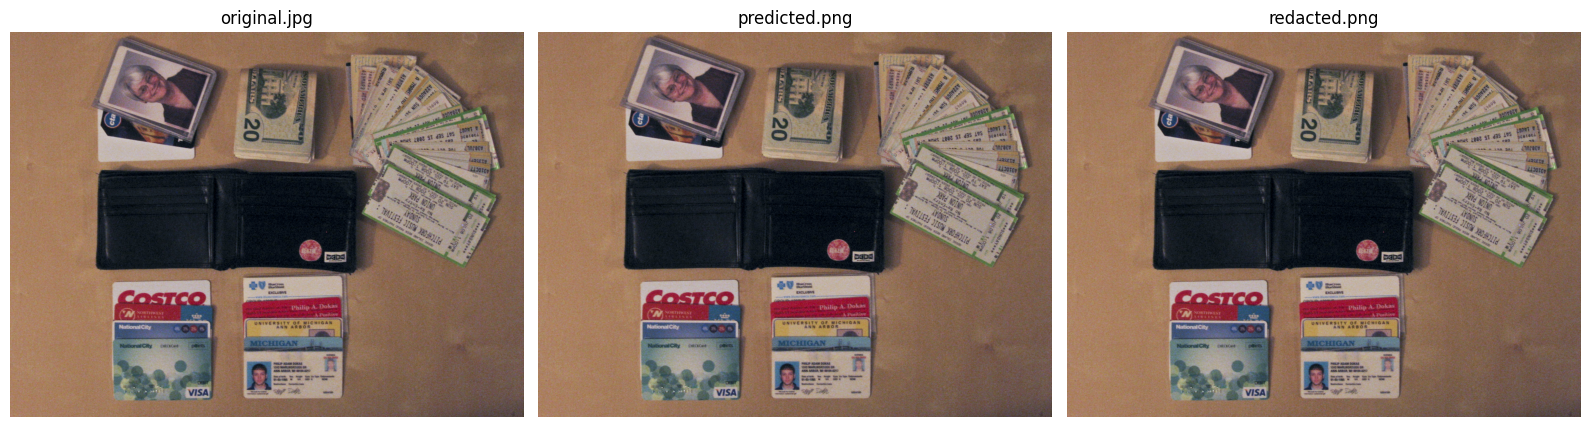

In [13]:
# Choose any index after the run, including an error, to inspect its artifacts.
all_results=read_json(report_dir/'all_results.json')
INSPECT_INDEX=2
if all_results:
    item=all_results[min(INSPECT_INDEX,len(all_results)-1)]
    row=next(r for r in cohort if r['id']==item['image_id'])
    folder=run_dir/item['model_key']/row['category']/Path(row['filename']).stem
    display(Markdown(f"### {item['model_key']} / {row['filename']} / {item['status']}"))
    display(item.get('evaluation',{'error':item.get('error')}))
    artifacts=[*folder.glob('original.*'),folder/'predicted.png']
    if item['status']=='ok':artifacts.append(folder/'redacted.png')
    fig,axes=plt.subplots(1,3,figsize=(16,6))
    for ax in axes:ax.axis('off');ax.set_title('Not generated after failure')
    for ax,path in zip(axes,artifacts):
        if path.exists():
            with Image.open(path) as im:ax.imshow(im.copy())
        ax.set_title(path.name if path.exists() else 'Not generated after failure');ax.axis('off')
    plt.tight_layout();plt.show()
else:
    print('No image outputs yet. Inspect the per-model stage failures in the report.')

## 9 Retry cloud backup without rerunning inference
    Every copied artifact is checked by read-back SHA-256 through the mounted Drive
    filesystem. Matching files are skipped. This verifies the mounted copy, not an
    independent Google server durability guarantee. Download the whole run folder to
    preserve relative image links in report.html. Credentials are never included.

In [10]:
backup(PROJECT,CATEGORY,run_dir.name)

Cloud copy and verify:   0%|          | 0/103 [00:00<?, ?file/s]

{"time": "2026-10-19T23:08:39.804426+00:00", "message": "Drive filesystem backup verified", "files": 103, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/data/vispr_eval_50", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}


Cloud copy and verify:   0%|          | 0/82 [00:00<?, ?file/s]

{"time": "2026-10-19T23:08:40.267777+00:00", "message": "Drive filesystem backup verified", "files": 82, "destination": "/content/drive/MyDrive/Leak_Benchmark_Results/benchmark_v2/results/vlm/20261019T230132317596Z", "verification_scope": "Read-back hashes through mounted Drive; remote server durability is not independently queried"}


[{'path': 'configs/historical_baseline.json',
  'sha256': '80313fe38206b279a05878a49925f579b297deba34418f400d33fb204338501e',
  'status': 'already_verified'},
 {'path': 'configs/models.json',
  'sha256': 'ae1b79dbd93b17c38b05bdf146dc90f7918d7666f0d75423cbf433985f2b5a14',
  'status': 'already_verified'},
 {'path': 'configs/selection.json',
  'sha256': 'e9f1c00e945fee45c12fa2f07c7d8be2e9fab7ae233a7465b2c3af293b922a28',
  'status': 'already_verified'},
 {'path': 'configs/taxonomy_crosswalk.csv',
  'sha256': 'ed90c544c6f9bee1608c1ff86c7f2af0ea7aa447d2212803e17ad359ca97b74b',
  'status': 'already_verified'},
 {'path': 'configs/training_plan.json',
  'sha256': '8d7ef5338435f3533c680399b82178afdc3e60f1e823ab044ceb40199bf1b6e0',
  'status': 'already_verified'},
 {'path': 'llama32_vision/gpu_samples.jsonl',
  'sha256': '77b60cd4545cb4988808e822806959c6df848fd2a218c405c90a729dce947b71',
  'status': 'already_verified'},
 {'path': 'llama32_vision/job.json',
  'sha256': '797d0fb5c3807deb8f6ccb14d90

In [15]:
# 1. Zip the folder (Replace 'my_folder' with your actual folder name)
!zip -r /content/Show-Me-The-Leak-v2/results.zip /content/Show-Me-The-Leak-v2/results

# 2. Download the zip file to your computer
from google.colab import files
files.download("/content/Show-Me-The-Leak-v2/results.zip")


  adding: content/Show-Me-The-Leak-v2/results/ (stored 0%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/ (stored 0%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/ (stored 0%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/ (stored 0%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/shared_text_scope_per_category.csv (deflated 92%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/summary.json (deflated 76%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/image_timings.csv (deflated 48%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/shared_text_scope_per_attribute.csv (deflated 94%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/full_taxonomy_per_category.csv (deflated 93%)
  adding: content/Show-Me-The-Leak-v2/results/vlm/20261019T230132317596Z/reports/full

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>